In [ ]:
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pandas.errors import SettingWithCopyWarning
#from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

warnings.simplefilter("ignore", SettingWithCopyWarning)

LOAD DATASETES

In [2]:
# BoardGameGeek dataset
bgg_dataset = pd.read_csv("bgg_dataset.csv", sep=';')

# Product/edition dataset
df = pd.read_csv('products_with_edition.csv')
df = df.drop(columns=['price_in_usd'])  # Remove unnecessary column

## convert currencies to USD

In [3]:
df = pd.read_csv('products_with_edition.csv')
df = df.drop(columns=['price_in_usd'])
df

def convert_to_usd(amount, currency, rates):
    currency = str(currency).upper()
    if currency not in rates or pd.isna(amount):
        return None
    return round(float(amount) * rates[currency], 2)

rates = {
    'USD': 1.0,
    'EUR': 1.10,
    'GBP': 1.30,
    'AUD': 0.65,
    'CAD': 0.75,
    'CHF': 1.05,
    'SGD': 0.73,
    'SEK': 0.10,
    'PLN': 0.24,
    'HUF': 0.0027,
    'MXN': 0.057,
    'NZD': 0.60,
    'JPY': 0.0073,
    'CNY': 0.14,
    'BRL': 0.19,
    'CZK': 0.042,
    'MYR': 0.21,
}

df['currency'] = df['currency'].str.upper()

df['price'] = df['price'] * df['currency'].map(rates)

df['currency'] = 'USD'

df['price'] = df['price'].round(2)
df

,productid,objecttype,objectid,producthref,price,currency,currencystring,currencysymbol,condition,prettycondition,...,quantity,userId,username,user_country,user_city,version_name,version_href,game_name,game_href,linkeduserGeekMarket
0,3870857,thing,1,/market/product/3870857,30.00,USD,U.S. dollars,$,likenew,Like New,...,1,2954044,LeBao,United States,Tallahassee,Die Macher (Multilingual edition 2006),/boardgameversion/24534/multilingual-edition-2006,Die Macher,/boardgame/1/die-macher,NaN
1,3866054,thing,1,/market/product/3866054,180.00,USD,U.S. dollars,$,new,New,...,1,3677448,CarsonChandler,United States,Christiansburg,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
2,3854476,thing,1,/market/product/3854476,41.99,USD,U.S. dollars,$,likenew,Like New,...,1,215794,Eric Engelmann,United States,Rockville,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
3,3853310,thing,1,/market/product/3853310,66.00,USD,Euros,€,new,New,...,1,1613268,JillySilly,Belgium,NaN,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
4,3845442,thing,1,/market/product/3845442,50.00,USD,U.S. dollars,$,verygood,Very Good,...,1,38240,caesarmom,United States,Lorton,Die Macher (German-only second edition),/boardgameversion/24939/german-only-second-edi...,Die Macher,/boardgame/1/die-macher,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178007,2589638,thing,99992,/market/product/2589638,11.00,USD,Euros,€,new,New,...,1,9646,Edgar Gallego,Spain,Sarriguren,NaN,NaN,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN
178008,2545360,thing,99992,/market/product/2545360,5.00,USD,U.S. dollars,$,likenew,Like New,...,1,840122,ohkoolnerd,United States,Struthers,Kill Shot: The Counter-Terrorism Party Game (E...,/boardgameversion/101405/english-edition,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN
178009,2136397,thing,99992,/market/product/2136397,8.00,USD,U.S. dollars,$,likenew,Like New,...,1,102667,Strom40,United States,Ypsilanti,Kill Shot: The Counter-Terrorism Party Game (E...,/boardgameversion/101405/english-edition,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN
178010,1372069,thing,99992,/market/product/1372069,13.00,USD,U.S. dollars,$,new,New,...,1,681464,biphead1,United States,Queens,NaN,NaN,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN


CLEAN PRODUCT DATA

In [4]:
cols_to_keep = ["objectid", "price", "version_name", "condition"]
products_clean = df.loc[:, cols_to_keep].copy()

# Drop missing IDs/prices
products_clean = products_clean.dropna(subset=["objectid", "price"])

# Convert types
products_clean["objectid"] = pd.to_numeric(products_clean["objectid"], errors="coerce").astype('Int64')
products_clean["price"] = pd.to_numeric(products_clean["price"], errors="coerce")

# Standardize condition
products_clean["condition"] = products_clean["condition"].astype(str).str.lower().str.strip()

# Keep only 'new' condition
products_clean = products_clean[products_clean["condition"] == "new"]

# Clean version names
products_clean["version_name"] = products_clean["version_name"].astype(str).str.strip()

# Remove duplicates
products_clean = products_clean.drop_duplicates(subset=["objectid", "version_name", "condition", "price"])

# Average price for duplicate versions
products_clean_avg = products_clean.groupby(
    ["objectid", "version_name", "condition"], as_index=False
)["price"].mean()

# IQR-based outlier removal
Q1 = products_clean_avg["price"].quantile(0.25)
Q3 = products_clean_avg["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

products_model_ready = products_clean_avg[
    (products_clean_avg["price"] >= lower_bound) & 
    (products_clean_avg["price"] <= upper_bound)
]

CLEAN BGG DATA

In [5]:
# Numeric conversion
numeric_cols = ['Year Published', 'Rating Average', 'Complexity Average', 'BGG Rank']
int_cols = ['Min Players', 'Max Players', 'Play Time', 'Min Age', 'Users Rated', 'Owned Users']

for col in numeric_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col].astype(str).str.replace(',', '.'), errors='coerce')
for col in int_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col], errors='coerce')

# Strip text
for col in ['Name', 'Mechanics', 'Domains']:
    bgg_dataset[col] = bgg_dataset[col].astype(str).str.strip()

# Drop rows with missing values
bgg_cleaned = bgg_dataset.dropna().copy()

MERGE PRODUCT DATA WITH BGG DATA

In [6]:
bgg_cleaned['ID'] = pd.to_numeric(bgg_cleaned['ID'], errors='coerce')
products_model_ready['objectid'] = pd.to_numeric(products_model_ready['objectid'], errors='coerce')

# Filter products in BGG
products_model_ready = products_model_ready[products_model_ready['objectid'].isin(bgg_cleaned['ID'])]

# Aggregate by version
products_grouped = products_model_ready.groupby(['objectid', 'version_name'], as_index=False).agg({
    'price': 'mean',
    'condition': 'first'
})

# Merge
bgg_merged = bgg_cleaned.merge(
    products_grouped[['objectid', 'price', 'condition', 'version_name']],
    how='left', left_on='ID', right_on='objectid'
)
bgg_merged.drop(columns=['objectid'], inplace=True)

# Clean unrealistic values
bgg_merged = bgg_merged[
    (bgg_merged['Year Published'] >= 1900) &
    (bgg_merged['Min Players'] > 0) &
    (bgg_merged['Max Players'] <= 20) &
    (bgg_merged['Play Time'] <= 600) &
    (bgg_merged['Min Age'] >= 0) &
    ((bgg_merged['price'].isna()) | (bgg_merged['price'] <= 300))
]

bgg_final = bgg_merged.dropna(subset=['price', 'version_name', 'condition'])
bgg_final.rename(columns={'BGG Rank': 'Success Rank'}, inplace=True)

DATA PREPROCESSING AND LABELING

In [12]:
# Complexity label
bgg_final["complexity_label"] = pd.cut(
    bgg_final["Complexity Average"], bins=[0, 2, 3.5, 5],
    labels=["Easy", "Medium", "Hard"], include_lowest=True
)

# High rating flag
bgg_final["highly_rated"] = bgg_final["Rating Average"] >= 8

# Game type classification
def classify_game_type(domains):
    if pd.isna(domains):
        return "Unknown"
    d = domains.lower()
    strategy_keywords = ["strategy", "abstract", "war", "wargame", "economic"]
    thematic_keywords = ["thematic", "adventure", "fantasy", "horror", "science fiction", "story", "exploration"]
    family_keywords = ["family", "children", "party", "puzzle", "dexterity", "trivia"]
    is_strategy = any(k in d for k in strategy_keywords)
    is_thematic = any(k in d for k in thematic_keywords)
    is_family = any(k in d for k in family_keywords)
    if is_strategy and is_thematic: return "Hybrid"
    elif is_strategy: return "Strategy"
    elif is_thematic: return "Thematic"
    elif is_family: return "Family/Party"
    else: return "Other"

bgg_final["game_type"] = bgg_final["Domains"].apply(classify_game_type)

# Price category
bgg_final["price_category"] = pd.cut(
    bgg_final["price"], bins=[0, 20, 50, 100, 500, 1000],
    labels=["very low", "low", "medium", "high", "very high"]
)

# Value-for-money features
bgg_final["rating_per_dollar"] = bgg_final["Rating Average"] / bgg_final["price"]
bgg_final["complexity_per_dollar"] = bgg_final["Complexity Average"] / bgg_final["price"]

# Mechanic annotation
mechanic_map = {
    "dice-driven": ["dice", "roll", "yahtzee"],
    "worker-placement": ["worker placement", "placement"],
    "deck-building": ["deck building", "deckbuilding"],
    "drafting": ["draft", "card drafting"],
    "tile-placement": ["tile placement", "domino", "polyomino"],
    "area-control": ["area control", "area majority"],
    "resource-management": ["resource", "economy", "produce"],
    "engine-building": ["engine", "combo", "synergy"],
    "set-collection": ["set collection"],
    "hand-management": ["hand management"],
    "card-based": ["card", "deck", "hand"],
    "co-op": ["cooperative", "co-op", "team"],
    "campaign-legacy": ["legacy", "campaign", "scenario"],
    "hidden-information": ["hidden", "secret", "deduction"],
    "bluffing": ["bluff", "traitor"],
    "puzzle": ["puzzle", "logic"],
    "party": ["party", "social"],
    "conflict-combat": ["combat", "fight", "battle"],
    "trading-negotiation": ["trade", "negotiation"]
}

def annotate_mechanics(text):
    if pd.isna(text):
        return ["other"]
    parts = [p.strip().lower() for p in text.split(",")]
    matched = set()
    for part in parts:
        for label, keywords in mechanic_map.items():
            if any(kw in part for kw in keywords):
                matched.add(label)
    return list(matched) if matched else ["other"]

bgg_final["Mechanics_annotated"] = bgg_final["Mechanics"].apply(annotate_mechanics)

# Explode for analysis
bgg_exploded = bgg_final.explode("Mechanics_annotated")

bgg_model_ready = bgg_final.drop(
    columns=["Name", "Mechanics", "Domains"]
)



FINAL DATASETS

In [13]:
bgg_final.to_csv("bgg_final.csv", index=False)
bgg_model_ready.to_csv("bgg_model_ready.csv", index=False)
bgg_exploded.to_csv("bgg_mechanics_exploded.csv", index=False)

print("✅ All datasets saved successfully")
print("Model-ready dataset shape:", bgg_model_ready.shape)
print("Final BGG dataset shape:", bgg_final.shape)
print("Exploded mechanics dataset shape:", bgg_exploded.shape)

✅ All datasets saved successfully
Model-ready dataset shape: (22826, 21)
Final BGG dataset shape: (22826, 24)
Exploded mechanics dataset shape: (49098, 24)


EDA: EXPLORATORY DATA ANALYSIS


C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


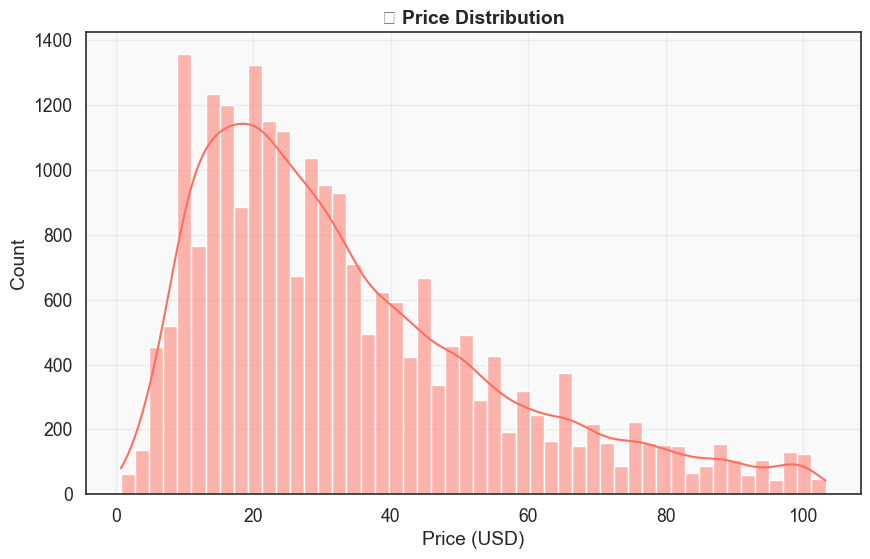

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


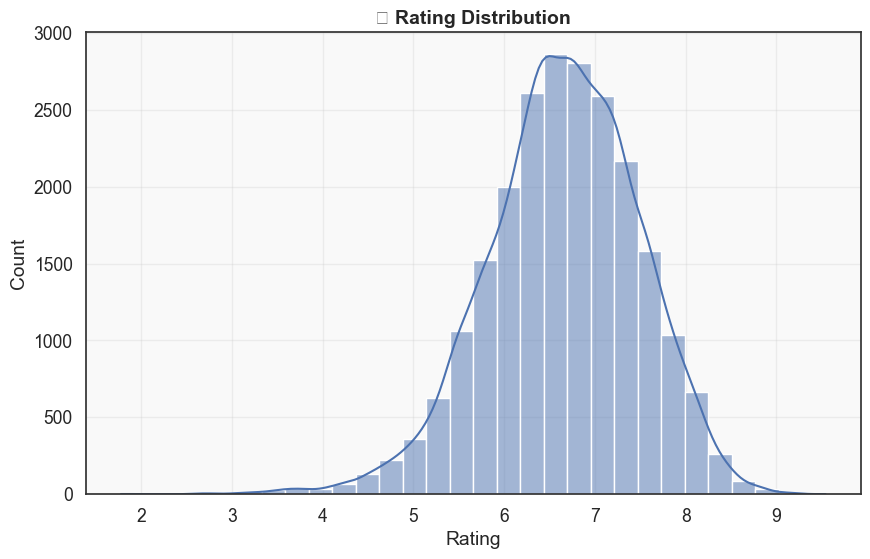

C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\966448089.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127918 (\N{VIDEO GAME}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


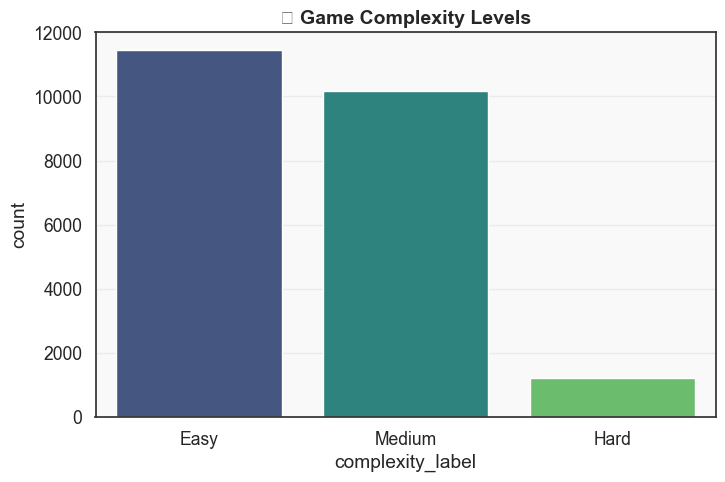

C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\966448089.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129513 (\N{JIGSAW PUZZLE PIECE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


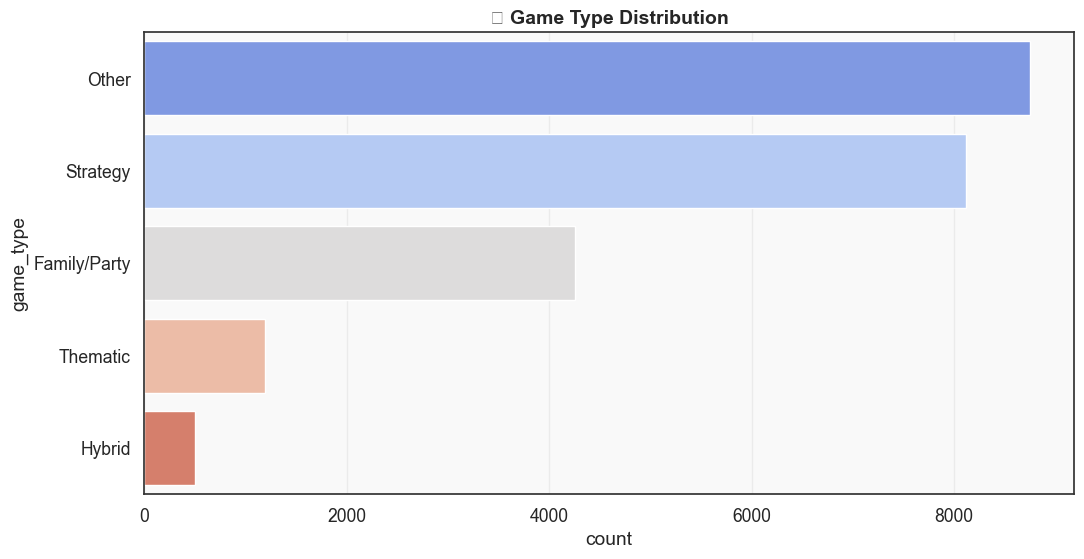

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128184 (\N{MONEY WITH WINGS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


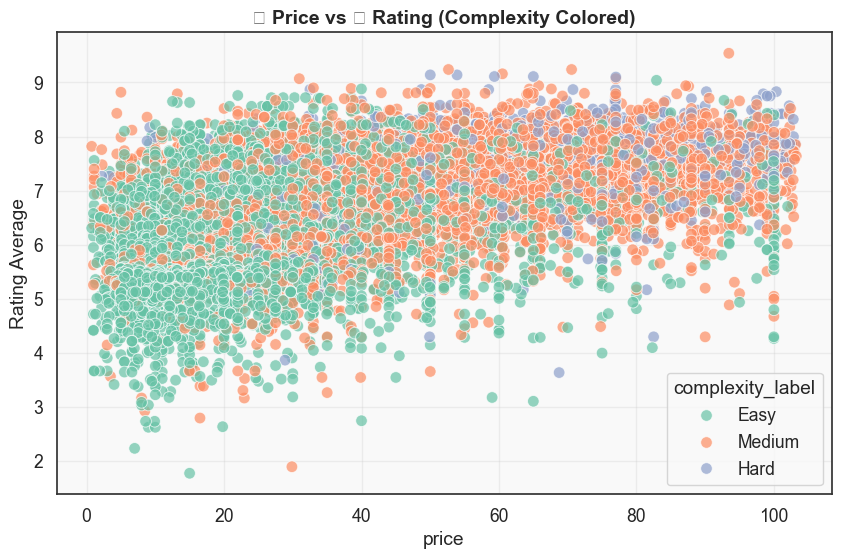

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


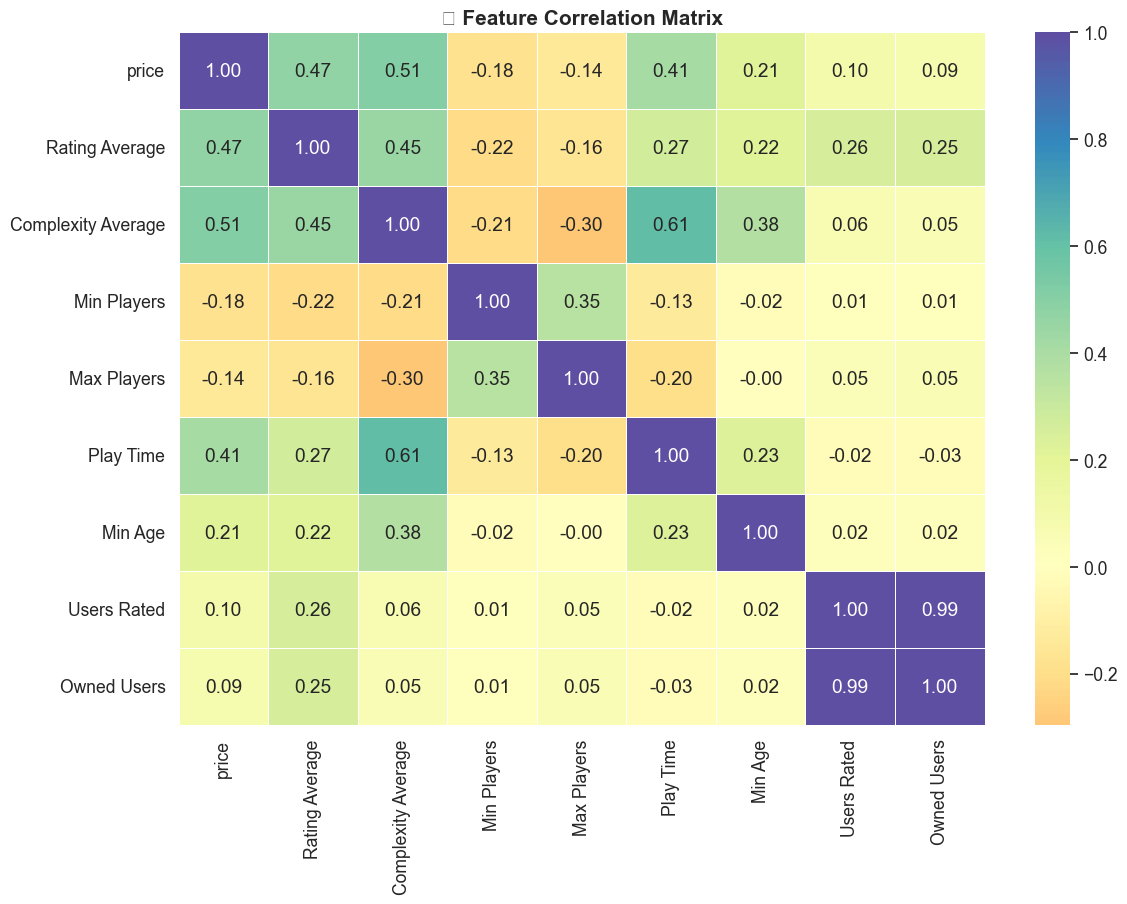

C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\966448089.py:106: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9881 (\N{GEAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


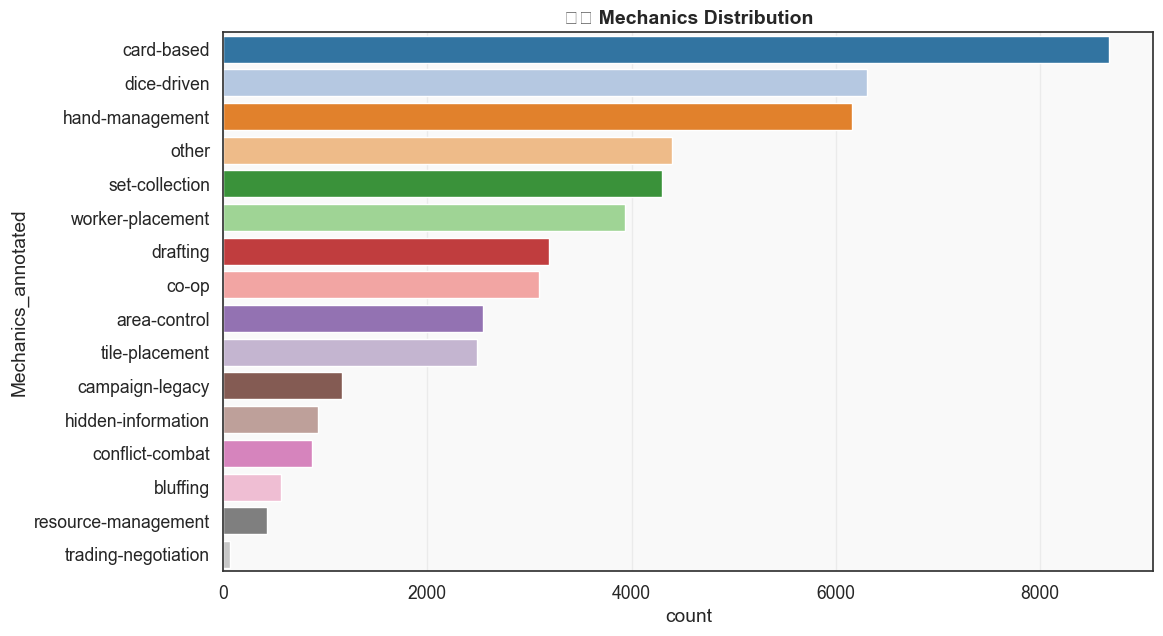

C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\966448089.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127991 (\N{LABEL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


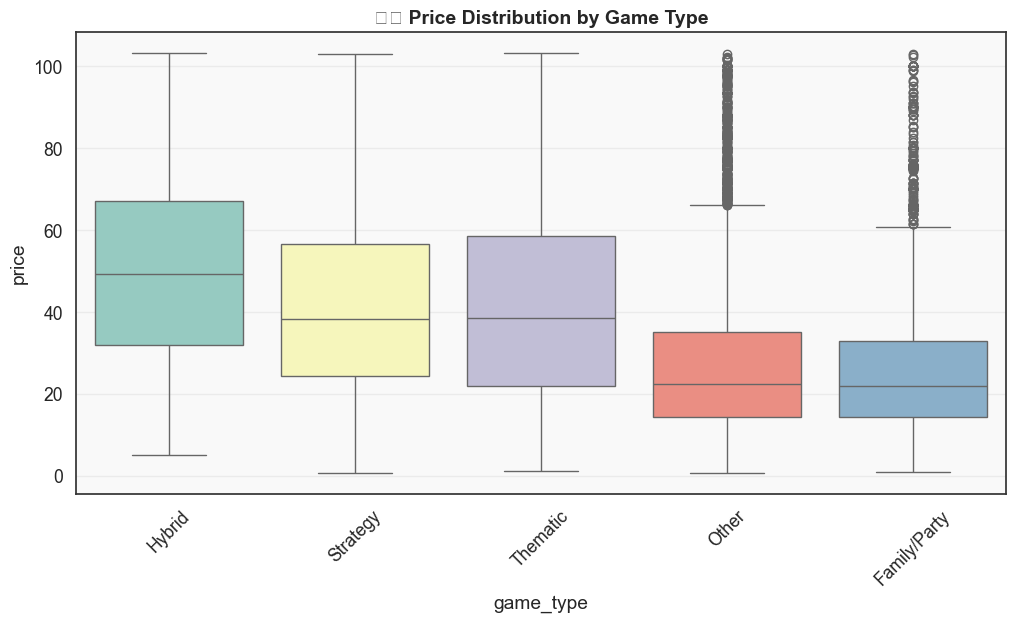

C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\966448089.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


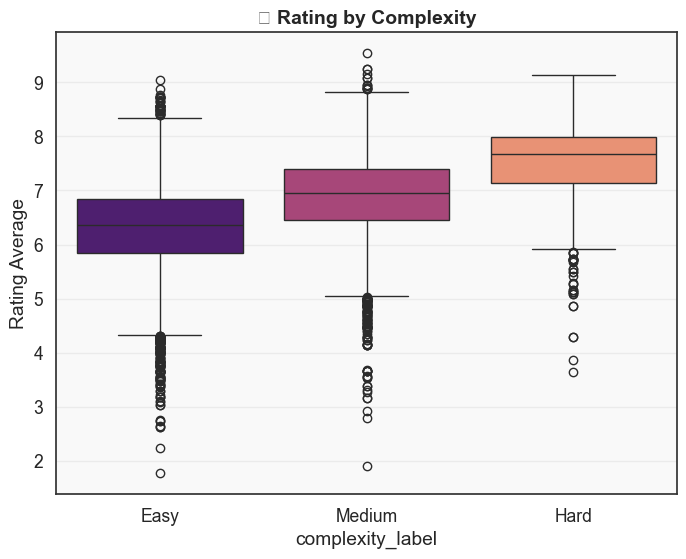

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


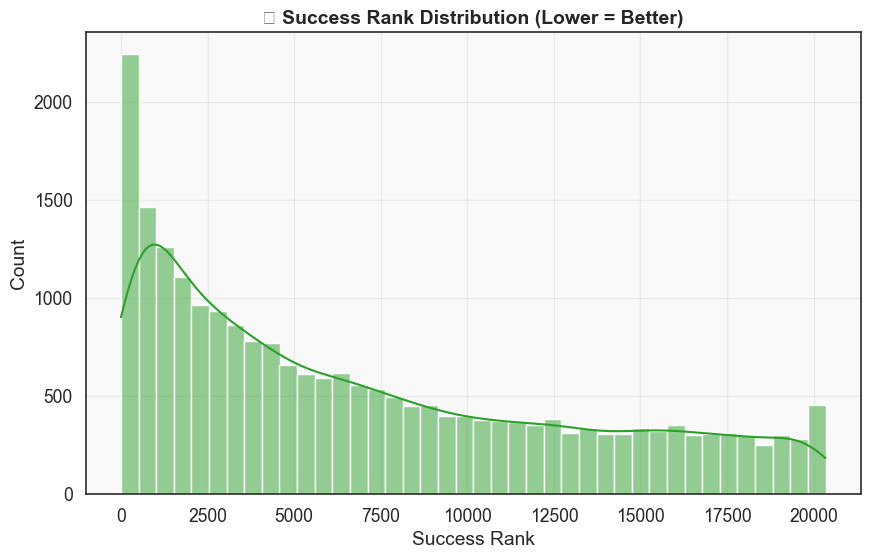

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


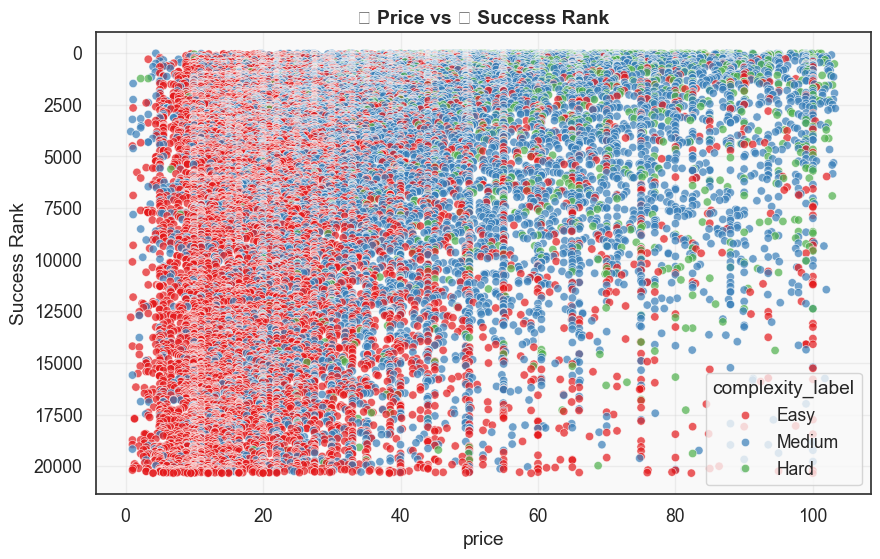

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


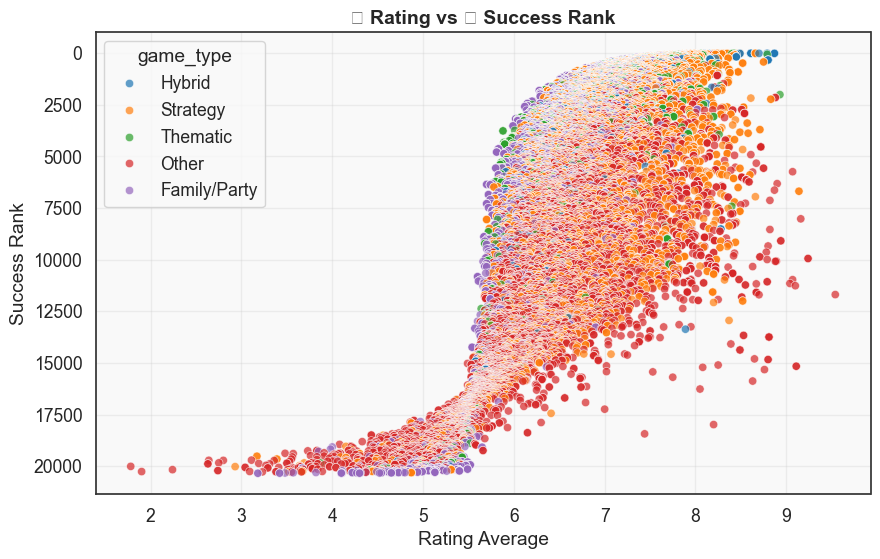

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


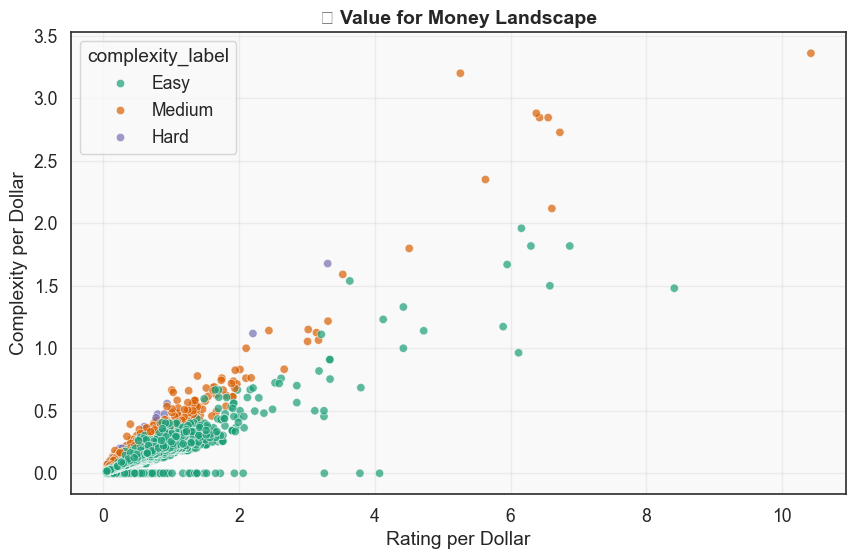

C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


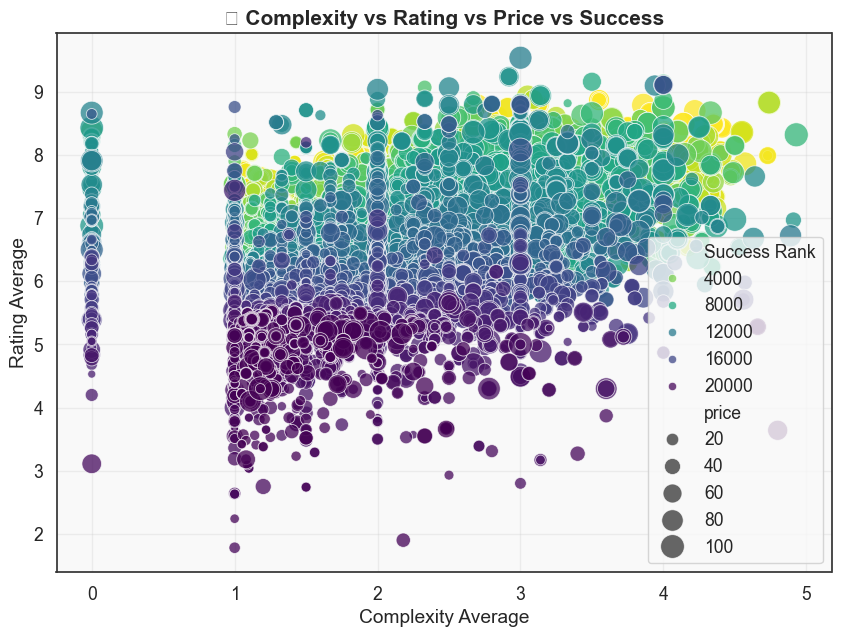

C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\966448089.py:222: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


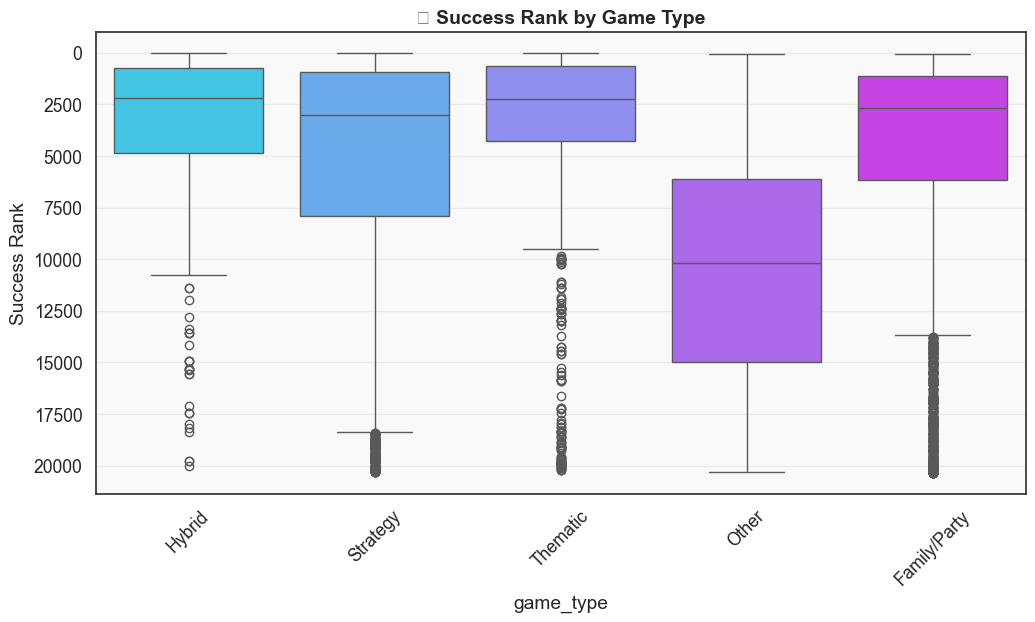

In [ ]:

sns.set_theme(
    style="whitegrid",
    palette="Spectral",
    font_scale=1.15,
    rc={
        "axes.facecolor": "#f9f9f9",
        "grid.alpha": 0.3,
        "axes.edgecolor": "0.2",
        "figure.facecolor": "white"
    }
)


# PRICE DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final['price'], bins=50, kde=True, color="#ff6f61")
plt.title("💰 Price Distribution", fontsize=14, weight="bold")
plt.xlabel("Price (USD)")
plt.ylabel("Count")
plt.show()


#  RATING DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final['Rating Average'], bins=30, kde=True, color="#4c72b0")
plt.title("⭐ Rating Distribution", fontsize=14, weight="bold")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()


# COMPLEXITY LABEL

plt.figure(figsize=(8,5))
sns.countplot(
    x="complexity_label",
    data=bgg_final,
    order=["Easy","Medium","Hard"],
    palette="viridis"
)
plt.title("🎮 Game Complexity Levels", fontsize=14, weight="bold")
plt.show()


#  GAME TYPE DISTRIBUTION

plt.figure(figsize=(12,6))
sns.countplot(
    y="game_type",
    data=bgg_final,
    order=bgg_final["game_type"].value_counts().index,
    palette="coolwarm"
)
plt.title("🧩 Game Type Distribution", fontsize=14, weight="bold")
plt.show()


#  PRICE vs RATING

plt.figure(figsize=(10,6))
sns.scatterplot(
    x="price",
    y="Rating Average",
    hue="complexity_label",
    palette="Set2",
    data=bgg_final,
    alpha=0.7,
    s=70
)
plt.title("💸 Price vs ⭐ Rating (Complexity Colored)", fontsize=14, weight="bold")
plt.show()

 
# CORRELATION HEATMAP

numeric_cols = [
    "price", "Rating Average", "Complexity Average", 
    "Min Players", "Max Players", "Play Time", 
    "Min Age", "Users Rated", "Owned Users"
]

plt.figure(figsize=(13,9))
sns.heatmap(
    bgg_final[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="Spectral",
    center=0,
    linewidths=0.6
)
plt.title("📊 Feature Correlation Matrix", fontsize=15, weight="bold")
plt.show()


#  MECHANICS DISTRIBUTION

plt.figure(figsize=(12,7))
sns.countplot(
    y="Mechanics_annotated",
    data=bgg_exploded,
    order=bgg_exploded["Mechanics_annotated"].value_counts().index,
    palette="tab20"
)
plt.title("⚙️ Mechanics Distribution", fontsize=14, weight="bold")
plt.show()


#  PRICE BY GAME TYPE

plt.figure(figsize=(12,6))
sns.boxplot(
    x="game_type",
    y="price",
    data=bgg_final,
    palette="Set3"
)
plt.xticks(rotation=45)
plt.title("🏷️ Price Distribution by Game Type", fontsize=14, weight="bold")
plt.show()


#  RATING BY COMPLEXITY

plt.figure(figsize=(8,6))
sns.boxplot(
    x="complexity_label",
    y="Rating Average",
    data=bgg_final,
    order=["Easy","Medium","Hard"],
    palette="magma"
)
plt.title("🧠 Rating by Complexity", fontsize=14, weight="bold")
plt.show()


#  SUCCESS RANK DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final["Success Rank"], bins=40, kde=True, color="#2ca02c")
plt.title("🏆 Success Rank Distribution (Lower = Better)", fontsize=14, weight="bold")
plt.xlabel("Success Rank")
plt.show()


#  PRICE vs SUCCESS RANK

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=bgg_final,
    x="price",
    y="Success Rank",
    hue="complexity_label",
    palette="Set1",
    alpha=0.7
)
plt.gca().invert_yaxis()
plt.title("💰 Price vs 🏆 Success Rank", fontsize=14, weight="bold")
plt.show()


#  RATING vs SUCCESS RANK

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=bgg_final,
    x="Rating Average",
    y="Success Rank",
    hue="game_type",
    palette="tab10",
    alpha=0.7
)
plt.gca().invert_yaxis()
plt.title("⭐ Rating vs 🏆 Success Rank", fontsize=14, weight="bold")
plt.show()


# 💎 VALUE FOR MONEY

plt.figure(figsize=(10,6))
sns.scatterplot(
    x="rating_per_dollar",
    y="complexity_per_dollar",
    hue="complexity_label",
    palette="Dark2",
    data=bgg_final,
    alpha=0.7
)
plt.title("💎 Value for Money Landscape", fontsize=14, weight="bold")
plt.xlabel("Rating per Dollar")
plt.ylabel("Complexity per Dollar")
plt.show()


# ULTIMATE BUBBLE CHART

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=bgg_final,
    x="Complexity Average",
    y="Rating Average",
    size="price",
    hue="Success Rank",
    palette="viridis_r",
    sizes=(30, 300),
    alpha=0.75
)
plt.title("🎯 Complexity vs Rating vs Price vs Success", fontsize=15, weight="bold")
plt.show()


#  SUCCESS BY GAME TYPE

plt.figure(figsize=(12,6))
sns.boxplot(
    data=bgg_final,
    x="game_type",
    y="Success Rank",
    palette="cool"
)
plt.gca().invert_yaxis()
plt.xticks(rotation=45)
plt.title("🏆 Success Rank by Game Type", fontsize=14, weight="bold")
plt.show()


### Mechanics Associated with more successful game

C:\Users\Abdel\AppData\Local\Temp\ipykernel_19972\4095497505.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




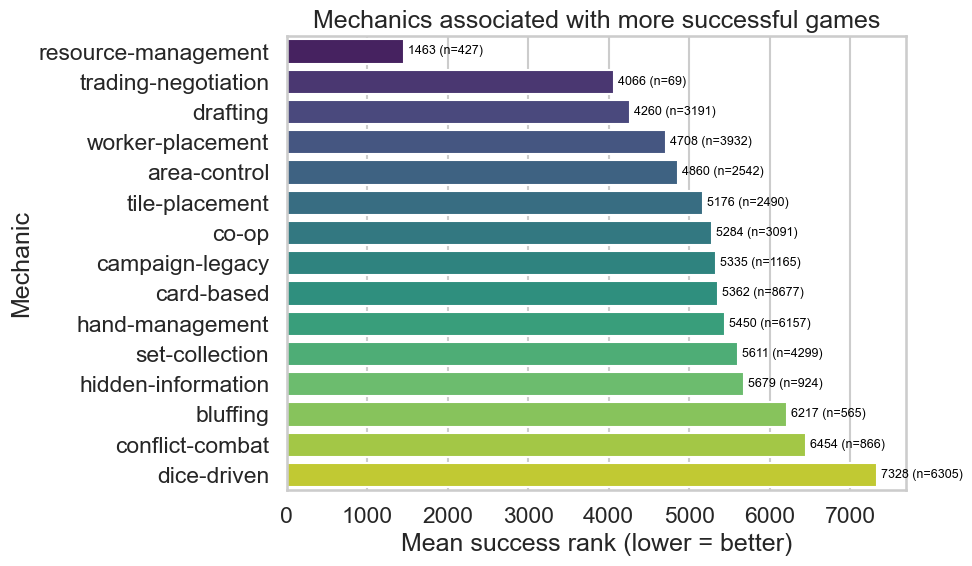

In [63]:
mech_exploded = (
    bgg_final
    # just fill NaN lists with empty lists; no split
    .assign(Mechanics_annotated=bgg_final['Mechanics_annotated'].apply(
        lambda x: x if isinstance(x, list) else []
    ))
    .explode('Mechanics_annotated')
)

# now Mechanics_annotated contains single mechanic strings
mech_exploded['Mechanics_annotated'] = mech_exploded['Mechanics_annotated'].astype(str).str.strip()
mech_exploded = mech_exploded[mech_exploded['Mechanics_annotated'] != ""]

mech_summary = (
    mech_exploded
    .groupby('Mechanics_annotated', as_index=False)
    .agg(mean_rank=('Success Rank', 'mean'),
         count=('Success Rank', 'size'))
    .dropna(subset=['mean_rank'])
    .sort_values('mean_rank')
)

mech_summary.head(15)

# Visualize
import seaborn as sns
import matplotlib.pyplot as plt

# pick mechanics with enough games and best average rank
plot_df = mech_summary.query('count >= 50').nsmallest(15, 'mean_rank')

sns.set_style("whitegrid")
sns.set_context("talk")  # slightly larger fonts

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=plot_df,
    y='Mechanics_annotated',
    x='mean_rank',
    palette='viridis'   # or 'mako', 'crest', etc.
)

plt.xlabel('Mean success rank (lower = better)')
plt.ylabel('Mechanic')
plt.title('Mechanics associated with more successful games')

# add value labels: mean rank and count
for i, row in plot_df.iterrows():
    ax.text(
        row['mean_rank'] + 50,  # a bit to the right of the bar
        ax.get_yticks()[list(plot_df.index).index(i)],
        f"{row['mean_rank']:.0f} (n={row['count']})",
        va='center',
        fontsize=9,
        color='black'
    )

plt.tight_layout()
plt.show()


Causal Inference: Success Rank

In [ ]:

# Define numeric confounders and treatments

numeric_cols = bgg_model_ready.select_dtypes(include=np.number).columns.tolist()
numeric_treatments = ['Rating Average', 'Complexity Average', 'price', 'Year Published', 'Min Players']
outcome = 'Success Rank'
numeric_confounders = list(set(numeric_cols) - set(numeric_treatments) - {outcome})
X_num = bgg_model_ready[numeric_confounders]

# Scale numeric confounders
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# -
#  Define categorical confounders

categorical_cols = ['game_type', 'price_category', 'Mechanics_annotated']
bgg_categorical = bgg_model_ready.dropna(subset=categorical_cols)
ohe = OneHotEncoder(drop='first', sparse_output=False)
X_cat = ohe.fit_transform(bgg_categorical[categorical_cols])

# Align indices
X_num_scaled_aligned = X_num_scaled[bgg_categorical.index, :]
X_combined = np.hstack([X_num_scaled_aligned, X_cat])


#  Define treatments

T = bgg_categorical[numeric_treatments]
Y = bgg_categorical[outcome]


#  Fit LinearDML

model_y = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
model_t = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

dml = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
dml.fit(Y=Y, T=T, X=X_combined)

# -------------------------------
# 6️⃣ Compute Average Treatment Effects (ATE)
# -------------------------------
effects = {}
for treatment in T.columns:
    dml_single = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
    dml_single.fit(Y=Y, T=T[[treatment]], X=X_combined)
    te = dml_single.effect(X=X_combined)
    effects[treatment] = te.mean()

# -------------------------------
# 7️⃣ Display results
# -------------------------------
print("✅ Causal Effects on Success Rank (Numeric + Categorical Confounders):")
for k, v in effects.items():
    print(f"{k}: {v:.4f}")


C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\econml\sklearn_extensions\linear_model.py:1815: UserWarning: Co-variance matrix is underdetermined. Inference will be invalid!
  warnings.warn("Co-variance matrix is underdetermined. Inference will be invalid!")
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array 

✅ Causal Effects on Success Rank (Numeric + Categorical Confounders):
Rating Average: -3657.5862
Complexity Average: -1440.4114
price: -603.8861
Year Published: -132.2390
Min Players: -11.5410


C:\Users\Abdel\AppData\Local\Temp\ipykernel_24024\3168638419.py:46: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  plt.tight_layout()


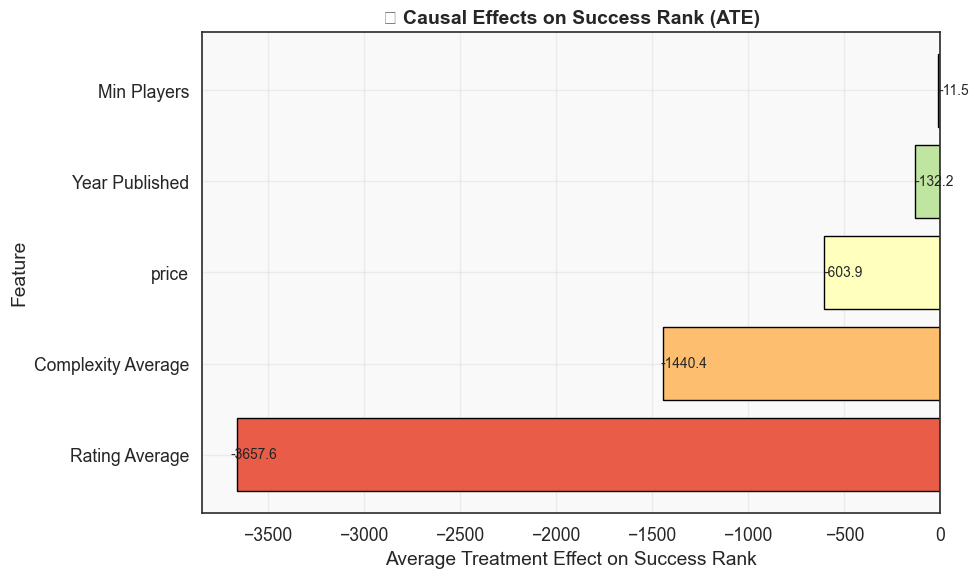

In [39]:



#  Causal Results

causal_results = {
    "Rating Average": -3657.5862,
    "Complexity Average": -1440.4114,
    "price": -603.8861,
    "Year Published": -132.2390,
    "Min Players": -11.5410
}

df_causal = pd.DataFrame.from_dict(
    causal_results, orient="index", columns=["ATE"]
).sort_values("ATE")


# BAR PLOT

plt.figure(figsize=(10, 6))

colors = sns.color_palette("Spectral", len(df_causal))

bars = plt.barh(
    df_causal.index,
    df_causal["ATE"],
    color=colors,
    edgecolor="black"
)

# Zero line
plt.axvline(0, color="black", linestyle="--", linewidth=1)

# Labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width * 1.01 if width < 0 else width * 1.01,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        va="center",
        fontsize=10
    )

plt.title("🎯 Causal Effects on Success Rank (ATE)", fontsize=14, weight="bold")
plt.xlabel("Average Treatment Effect on Success Rank")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

